# Mini-Project 4 – Rainfall Pattern & Crop Suitability Analyser

**OOP with Python, Assignment 1 (Advent 2026)** · Wesonga John Collins

An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers on which
months suit which crops. Reusable logic lives in `src/a1/rainfall.py` (`Region`, `CropRule`, similarity
functions and season detection), unit-tested in `tests/test_rainfall.py`.

## 0. Setup

In [1]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import scipy.spatial.distance

from a1.rainfall import (
    MONTHS,
    CropRule,
    Region,
    cosine_similarity,
    detect_rainy_seasons,
    similarity_matrices,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROMINENCE = 0.15          # season-detection rule, fixed before looking at results (see Section 6)
pd.set_option("display.precision", 3)

## 1. Data (illustrative, from the brief)

In [2]:
regions = [
    Region("Kampala", [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130]),
    Region("Gulu", [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15]),
    Region("Mbarara", [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90]),
]
pd.DataFrame({r.name: r.rainfall for r in regions}, index=MONTHS).T.astype(int)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Kampala,120,140,180,200,220,180,90,70,60,100,110,130
Gulu,8,25,75,160,190,145,170,215,175,150,60,15
Mbarara,70,85,120,140,90,25,20,55,100,125,120,90


## 2. Task 1 – the `Region` class

In [3]:
for r in regions:
    print(repr(r))
summary = pd.DataFrame({
    r.name: {"annual total (mm)": r.annual_total(), "mean (mm/month)": r.mean(),
             "wettest month": f"{r.wettest_month()[0]} ({r.wettest_month()[1]:.0f} mm)",
             "driest month": f"{r.driest_month()[0]} ({r.driest_month()[1]:.0f} mm)",
             "CV across months": r.cv()}
    for r in regions
}).T
summary

Region('Kampala', annual=1600 mm)
Region('Gulu', annual=1388 mm)
Region('Mbarara', annual=1040 mm)


,annual total (mm),mean (mm/month),wettest month,driest month,CV across months
Kampala,1600.0,133.333,May (220 mm),Sep (60 mm),0.388
Gulu,1388.0,115.667,Aug (215 mm),Jan (8 mm),0.642
Mbarara,1040.0,86.667,Apr (140 mm),Jul (20 mm),0.444


Kampala is the wettest region (1,600 mm a year) and the most evenly watered: even its driest month receives 60 mm, and its monthly CV (0.39) is the lowest. Gulu receives less in total (1,388 mm) but is by far the most seasonal (CV 0.64): almost nothing falls from December to February (8–25 mm), while August brings 215 mm. Mbarara is the driest (1,040 mm), with a pronounced dry spell in June–July (20–25 mm) between two wetter periods. Annual totals alone would hide these differences; for crops, the timing of rain matters as much as the amount.

## 3. Task 2 – crop rules with cited thresholds

The sources give water needs **per growing season** (or per year for coffee). Each is converted to a monthly
range by dividing by the length of the season:

| Crop | Source requirement | Season length used | Monthly range |
|---|---|---|---|
| Maize | 500–800 mm per growing period (FAO, Critchley & Siegert 1991, Table 2) | 5 months (grain maize 125–180 days, Table 6) | 100–160 mm |
| Beans (dry) | 300–500 mm per growing period (same table) | 3.5 months (dry beans 95–110 days, Table 6) | 86–143 mm |
| Robusta coffee | 1,200–1,500 mm a year, well distributed over about 9 months (NaCRRI 2010) | 9 months | 133–167 mm |

Sources: W. Critchley & K. Siegert (1991), *Water Harvesting*, FAO, Rome, ch. 2 — https://www.fao.org/4/u3160e/u3160e04.htm ;
National Crops Resources Research Institute (NaCRRI, 2010), *Establishment and field management of Robusta coffee*,
NARO — https://www.naroinfohub.naro.go.ug/RepDetails.aspx?pn=3940 . FAO's crop information page gives the same
500–800 mm figure for medium-maturity grain maize.

A month below the range is labelled *Drought risk*; above it, *Waterlogging risk* (more water than the crop
needs — whether it actually waterlogs depends on soil drainage, which is not modelled).

In [4]:
crops = [
    CropRule.from_seasonal("maize", 500, 800, 5, source="FAO (Critchley & Siegert 1991)"),
    CropRule.from_seasonal("beans", 300, 500, 3.5, source="FAO (Critchley & Siegert 1991)"),
    CropRule.from_seasonal("coffee", 1200, 1500, 9, source="NaCRRI (2010)"),
]
display(pd.DataFrame([{"crop": c.crop, "min (mm/month)": c.min_mm, "max (mm/month)": c.max_mm,
                       "derivation": c.derivation, "source": c.source} for c in crops]).set_index("crop").round(1))

labels = pd.DataFrame(
    {(r.name, c.crop): [c.classify(x) for x in r.rainfall] for r in regions for c in crops},
    index=MONTHS,
).T
labels.index.names = ["region", "crop"]
labels

,min (mm/month),max (mm/month),derivation,source
crop,,,,
maize,100.0,160.0,500-800 mm over 5 months,FAO (Critchley & Siegert 1991)
beans,85.7,142.9,300-500 mm over 3.5 months,FAO (Critchley & Siegert 1991)
coffee,133.3,166.7,1200-1500 mm over 9 months,NaCRRI (2010)


Jan              Feb                Mar  \
region  crop                                                         
Kampala maize   Good for maize   Good for maize  Waterlogging risk   
        beans   Good for beans   Good for beans  Waterlogging risk   
        coffee    Drought risk  Good for coffee  Waterlogging risk   
Gulu    maize     Drought risk     Drought risk       Drought risk   
        beans     Drought risk     Drought risk       Drought risk   
        coffee    Drought risk     Drought risk       Drought risk   
Mbarara maize     Drought risk     Drought risk     Good for maize   
        beans     Drought risk     Drought risk     Good for beans   
        coffee    Drought risk     Drought risk       Drought risk   

                              Apr                May                Jun  \
region  crop                                                              
Kampala maize   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        beans   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        coffee  Waterlogging risk  Waterlogging risk  Waterlogging risk   
Gulu    maize      Good for maize  Waterlogging risk     Good for maize   
        beans   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        coffee    Good for coffee  Waterlogging risk    Good for coffee   
Mbarara maize      Good for maize       Drought risk       Drought risk   
        beans      Good for beans     Good for beans       Drought risk   
        coffee    Good for coffee       Drought risk       Drought risk   

                              Jul                Aug                Sep  \
region  crop                                                              
Kampala maize        Drought risk       Drought risk       Drought risk   
        beans      Good for beans       Drought risk       Drought risk   
        coffee       Drought risk       Drought risk       Drought risk   
Gulu    maize   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        beans   Waterlogging risk  Waterlogging risk  Waterlogging risk   
        coffee  Waterlogging risk  Waterlogging risk  Waterlogging risk   
Mbarara maize        Drought risk       Drought risk     Good for maize   
        beans        Drought risk       Drought risk     Good for beans   
        coffee       Drought risk       Drought risk       Drought risk   

                              Oct             Nov             Dec  
region  crop                                                       
Kampala maize      Good for maize  Good for maize  Good for maize  
        beans      Good for beans  Good for beans  Good for beans  
        coffee       Drought risk    Drought risk    Drought risk  
Gulu    maize      Good for maize    Drought risk    Drought risk  
        beans   Waterlogging risk    Drought risk    Drought risk  
        coffee    Good for coffee    Drought risk    Drought risk  
Mbarara maize      Good for maize  Good for maize    Drought risk  
        beans      Good for beans  Good for beans  Good for beans  
        coffee       Drought risk    Drought risk    Drought risk

In [5]:
# How many suitable months each crop gets in each region
good_months = pd.DataFrame({c.crop: {r.name: sum(c.score(x) == 0 for x in r.rainfall) for r in regions}
                            for c in crops})
good_months.index.name = "region"
good_months.columns = [f"suitable months: {c}" for c in good_months.columns]
good_months.assign(**{"annual total (mm)": [r.annual_total() for r in regions]})

,suitable months: maize,suitable months: beans,suitable months: coffee,annual total (mm)
region,,,,
Kampala,5,6,1,1600.0
Gulu,3,0,3,1388.0
Mbarara,5,7,1,1040.0


Beans fit Mbarara best (7 suitable months: March–May and September–December) and Kampala reasonably (6 months), but fail in Gulu, where every wet month exceeds their range and the dry months fall far below it. Maize gets 5 suitable months in Kampala and in Mbarara but only 3 in Gulu. Kampala's March–June are flagged as excess for all three crops because 180–220 mm is more than the crops need. Coffee is suitable in only 1–3 months anywhere, which reveals a limitation of the method rather than of the regions: coffee is a perennial whose requirement is an annual total (1,200–1,500 mm), so a month-by-month rule is too strict. On that annual test Gulu (1,388 mm) is within range, Kampala (1,600 mm) slightly above and Mbarara (1,040 mm) below. "Waterlogging risk" here means more rain than the crop needs; whether fields actually waterlog depends on soil and drainage.

## 4. Task 3 – correcting last year's cosine similarity

`math.cos(x)` returns the cosine of an **angle** `x` in radians; applied to rainfall it is meaningless. Cosine
similarity between two vectors is $\cos\theta = \dfrac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$.
`scipy.spatial.distance.cosine` returns the cosine **distance** $1 - \cos\theta$, so the check is
`1 - cosine(a, b)`.

In [6]:
print("Wrong method, math.cos(1600) =", round(math.cos(1600), 4), "(cosine of 1600 radians)")
rows = []
for i, a in enumerate(regions):
    for b in regions[i + 1:]:
        ours = cosine_similarity(a.rainfall, b.rainfall)
        scipy_value = 1 - scipy.spatial.distance.cosine(a.rainfall, b.rainfall)
        assert np.isclose(ours, scipy_value)
        rows.append({"pair": f"{a.name}-{b.name}", "NumPy (dot / norms)": ours, "1 - scipy cosine": scipy_value})
pd.DataFrame(rows).set_index("pair")

Wrong method, math.cos(1600) = -0.5984 (cosine of 1600 radians)


,NumPy (dot / norms),1 - scipy cosine
pair,,
Kampala-Gulu,0.787,0.787
Kampala-Mbarara,0.891,0.891
Gulu-Mbarara,0.749,0.749


## 5. Task 4 – three similarity/distance measures

In [7]:
matrices = similarity_matrices(regions)
for name, m in matrices.items():
    print(name)
    display(m.round(3))

cosine similarity


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


Pearson correlation


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


Euclidean distance (mm)


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.4
Gulu,315.268,0.000,312.8
Mbarara,250.400,312.800,0.0


In [8]:
# Why cosine can call a much wetter region "similar": it measures the angle between vectors, not their size.
k = regions[0].rainfall
demo = pd.DataFrame({
    "Kampala x 2 (twice as wet)": {"cosine": cosine_similarity(k, 2 * k),
                                   "Pearson": np.corrcoef(k, 2 * k)[0, 1],
                                   "Euclidean (mm)": np.linalg.norm(k - 2 * k)},
    "Kampala + 100 mm every month": {"cosine": cosine_similarity(k, k + 100),
                                     "Pearson": np.corrcoef(k, k + 100)[0, 1],
                                     "Euclidean (mm)": np.linalg.norm(k - (k + 100))},
}).T
demo

,cosine,Pearson,Euclidean (mm)
Kampala x 2 (twice as wet),1.000,1.0,492.747
Kampala + 100 mm every month,0.989,1.0,346.410


The three measures disagree. Cosine similarity rates every pair as fairly similar (0.75–0.89, with Kampala–Mbarara the most similar), yet the Pearson correlations are close to zero or negative (−0.17 to 0.21), so the regions' month-to-month patterns barely move together. Euclidean distance, which measures absolute differences in mm, puts Kampala and Mbarara closest (250 mm) and Gulu furthest from both (313–315 mm). Cosine similarity compares only the **direction** of the rainfall vectors and ignores their size: Kampala at twice its rainfall scores a perfect 1.0, although it is 493 mm away in Euclidean terms. Because all rainfall values are positive, every vector also points into the same corner of the space, which inflates cosine similarity; Pearson correlation subtracts each region's mean first and so compares the shape of the seasonal cycle. For comparing rainfall regimes, Pearson (shape) and Euclidean distance (amount) together are more informative than cosine alone.

## 6. Task 5 – detecting rainy seasons with `scipy.signal.find_peaks`

Rule (fixed in advance): the year is treated as circular (December next to January) and a month counts as a
rainy-season peak if its prominence is at least **15 % of the region's annual range** (wettest minus driest
month). This keeps the rule scale-free across wet and dry regions. One peak → unimodal, two → bimodal.
A sensitivity check reports the result for other thresholds, so the conclusion is not hidden behind one choice.

In [9]:
seasons = pd.DataFrame({r.name: detect_rainy_seasons(r.rainfall, PROMINENCE) for r in regions}).T
display(seasons)

sensitivity = pd.DataFrame({
    f"{int(f * 100)} %": {r.name: detect_rainy_seasons(r.rainfall, f)["regime"] for r in regions}
    for f in (0.05, 0.10, 0.15, 0.20, 0.30)
})
sensitivity.columns.name = "prominence threshold"
sensitivity

,peaks,prominences,regime
Kampala,[May],[160.0],unimodal
Gulu,"[May, Aug]","[45.0, 207.0]",bimodal
Mbarara,"[Apr, Oct]","[120.0, 55.0]",bimodal


prominence threshold,5 %,10 %,15 %,20 %,30 %
Kampala,bimodal,unimodal,unimodal,unimodal,unimodal
Gulu,bimodal,bimodal,bimodal,bimodal,unimodal
Mbarara,bimodal,bimodal,bimodal,bimodal,bimodal


**Known climate zones.** Uganda's rainfall is bimodal near the equator — a main season in March–May and a shorter one in September–November — and unimodal in the north (Basalirwa 1995, summarised in Kisembe et al. 2018, *Theoretical and Applied Climatology*, https://link.springer.com/article/10.1007/s00704-018-2643-x). Kampala and Mbarara lie near the equator; Gulu (about 2.8° N) lies towards the northern, unimodal zone.

With the 15 % rule, **Mbarara** is clearly bimodal (peaks in April and October), matching the equatorial zone. **Gulu** is detected as bimodal, with a strong peak in August and a smaller one in May. This is consistent with its position towards the north, where the two seasons draw together into one long wet season: Gulu's June "trough" still receives 145 mm, so both peaks lie inside a single continuous wet period from about April to October. **Kampala** is detected as unimodal, which does **not** match its known bimodal climate: the illustrative series has only a weak second rise (October–December, peaking at 130 mm in December, just 10 mm above January), far smaller than its May peak. The sensitivity table shows Kampala becomes bimodal only at a 5 % threshold, while Gulu turns unimodal at 30 %. Detection of weak secondary peaks is therefore sensitive to the threshold, and the illustrative data understate Kampala's short rains; the real data in Section 9 provide a check.

## 7. Task 6 – charts

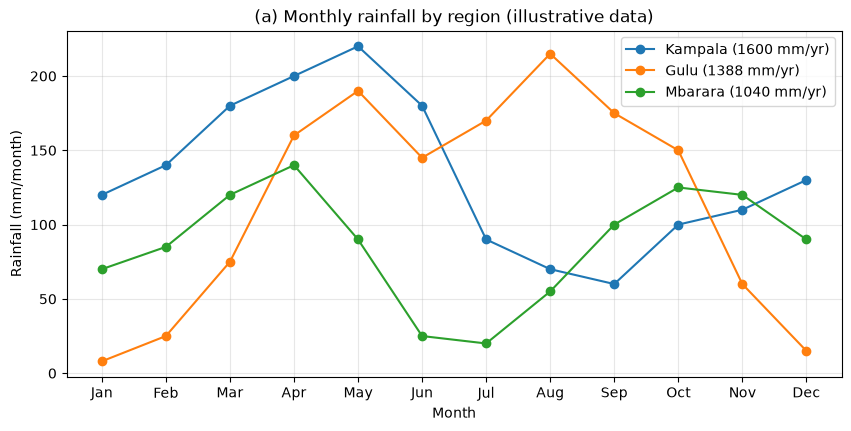

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for r in regions:
    ax.plot(MONTHS, r.rainfall, marker="o", label=f"{r.name} ({r.annual_total():.0f} mm/yr)")
ax.set_xlabel("Month")
ax.set_ylabel("Rainfall (mm/month)")
ax.set_title("(a) Monthly rainfall by region (illustrative data)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

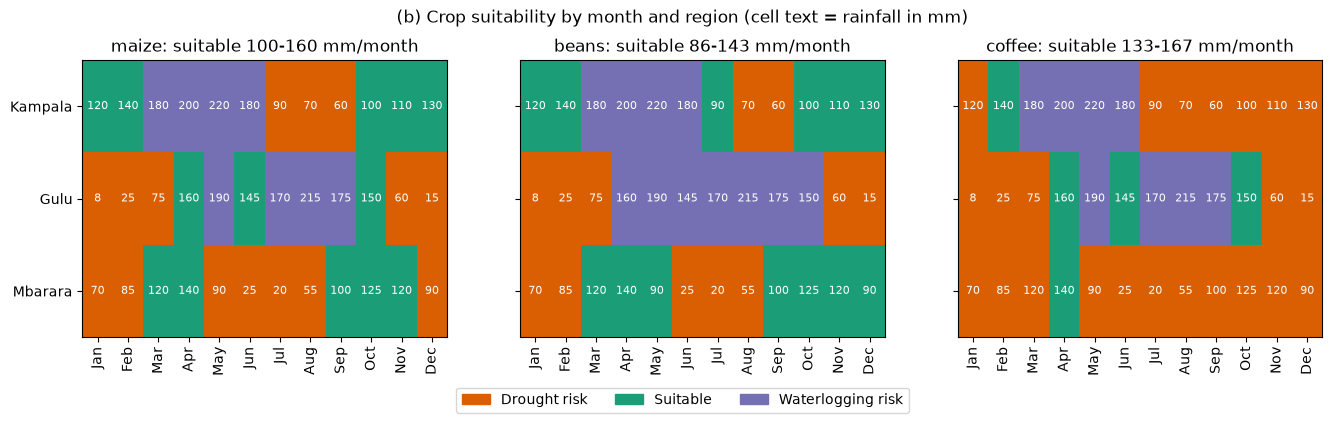

In [11]:
cmap = ListedColormap(["#d95f02", "#1b9e77", "#7570b3"])        # drought, suitable, waterlogging
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, c in zip(axes, crops):
    grid = np.array([[c.score(x) for x in r.rainfall] for r in regions])
    ax.imshow(grid, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(12):
            ax.text(j, i, f"{regions[i].rainfall[j]:.0f}", ha="center", va="center", fontsize=8, color="white")
    ax.set_xticks(range(12), MONTHS, rotation=90)
    ax.set_yticks(range(len(regions)), [r.name for r in regions])
    ax.set_title(f"{c.crop}: suitable {c.min_mm:.0f}-{c.max_mm:.0f} mm/month")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(k)) for k in range(3)]
fig.legend(handles, ["Drought risk", "Suitable", "Waterlogging risk"], loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.12))
fig.suptitle("(b) Crop suitability by month and region (cell text = rainfall in mm)", y=1.02)
plt.show()

The line chart shows the contrast in timing: Kampala's rain peaks in May and stays moderate all year, Gulu has a long wet season from April to October and a near-dry December–February, and Mbarara has two short wet periods separated by the June–July dry spell. The heatmap turns this into planting windows: the green (suitable) blocks for beans and maize line up with Mbarara's two seasons and Kampala's quieter months, while Gulu is mostly orange (drought) or purple (excess) for beans. It also makes the coffee limitation visible: a perennial crop judged month by month appears unsuitable almost everywhere.

## 8. Task 7 – advisory note for farmers

**Advisory note: bean farmers in Mbarara**

Mbarara has two rainy seasons each year, so you can grow beans twice. Beans need roughly 300–500 mm of water over a season of about three and a half months.

*First season:* plant at the start of the March rains. March, April and May usually bring 90–140 mm each, which suits beans; harvest in June, before the dry spell sets in.

*Second season:* plant in early September as the rains return. September to November bring 100–125 mm a month and December about 90 mm, enough to finish the crop; harvest from mid-December.

Avoid planting in June, July or August: rainfall drops to 20–55 mm a month and young plants will suffer drought. Maize is riskier here than beans, because its longer season (about five months) runs into the dry spell; if you grow maize, choose an early-maturing variety planted at the very start of the rains. Coffee needs 1,200–1,500 mm a year; Mbarara averaged about 1,310 mm in 2014–2023, so coffee is feasible in average years if mulched against dry ones.

Rainfall varies from year to year, so wait until the rains are established before planting.

## 9. Extension – real rainfall, 10 years (NASA POWER)

Monthly rainfall for 2014–2023 at Kampala, Gulu and Mbarara was downloaded by `scripts/fetch_nasa_power.py`
from the NASA POWER API (parameter `PRECTOTCORR`, MERRA-2 bias-corrected precipitation, reported in mm/day and
converted to monthly totals). *These data were obtained from the NASA Langley Research Center POWER Project
funded through the NASA Earth Science Directorate Applied Science Program* (https://power.larc.nasa.gov).
POWER values are gridded estimates (about 0.5° × 0.625°), not rain-gauge readings.

In [12]:
real = pd.read_csv(ROOT / "data" / "processed" / "rainfall_nasa_power.csv")
years = sorted(real["year"].unique())
print(f"{len(real)} monthly values, {years[0]}-{years[-1]}, regions: {real['region'].unique().tolist()}")

annual = real.groupby(["region", "year"])["rain_mm"].sum().unstack("region")
climatology = real.groupby(["region", "month"])["rain_mm"].mean().unstack("region")
climatology.index = MONTHS
comparison = pd.DataFrame({
    r.name: {"illustrative annual (mm)": r.annual_total(),
             "NASA POWER mean annual (mm)": annual[r.name].mean(),
             "NASA POWER annual range (mm)": f"{annual[r.name].min():.0f}-{annual[r.name].max():.0f}",
             "year-to-year CV of annual total (%)": annual[r.name].std(ddof=1) / annual[r.name].mean() * 100,
             "regime of 10-yr mean": detect_rainy_seasons(climatology[r.name].to_numpy(), PROMINENCE)["regime"],
             "peaks of 10-yr mean": detect_rainy_seasons(climatology[r.name].to_numpy(), PROMINENCE)["peaks"]}
    for r in regions
}).T
comparison

360 monthly values, 2014-2023, regions: ['Kampala', 'Gulu', 'Mbarara']


,illustrative annual (mm),NASA POWER mean annual (mm),NASA POWER annual range (mm),year-to-year CV of annual total (%),regime of 10-yr mean,peaks of 10-yr mean
Kampala,1600.0,1505.805,1107-1841,16.582,bimodal,"[Apr, Nov]"
Gulu,1388.0,1415.735,1109-2129,21.48,bimodal,"[May, Oct]"
Mbarara,1040.0,1313.67,880-1905,23.419,bimodal,"[Apr, Oct]"


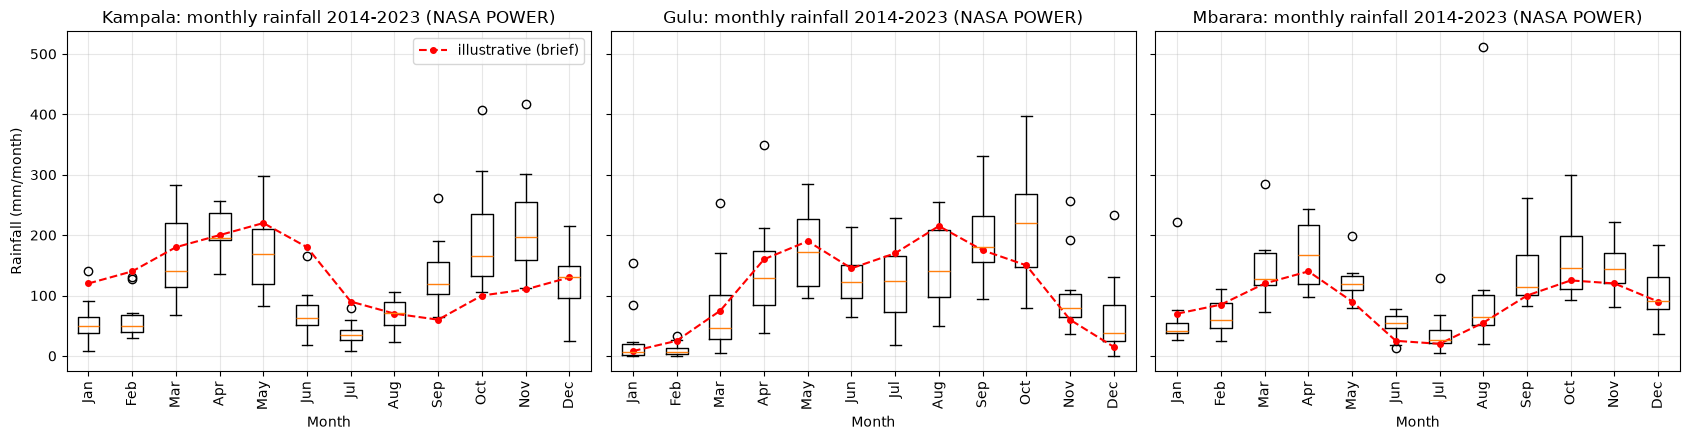

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, r in zip(axes, regions):
    by_month = [real.loc[(real["region"] == r.name) & (real["month"] == m), "rain_mm"].to_numpy()
                for m in range(1, 13)]
    ax.boxplot(by_month, tick_labels=MONTHS)
    ax.plot(range(1, 13), r.rainfall, "r--o", ms=4, label="illustrative (brief)")
    ax.set_title(f"{r.name}: monthly rainfall {years[0]}-{years[-1]} (NASA POWER)")
    ax.set_xlabel("Month")
    ax.tick_params(axis="x", rotation=90)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Rainfall (mm/month)")
axes[0].legend()
fig.tight_layout()
plt.show()

The real data change three conclusions. **Totals:** Kampala (1,506 mm) and Gulu (1,416 mm) are close to the illustrative figures, but Mbarara averages 1,314 mm, about 26 % more than the brief's 1,040 mm, which places it inside coffee's 1,200–1,500 mm range in an average year. **Seasonality:** with the same 15 % rule, all three 10-year mean profiles are bimodal, and Kampala now shows its known short-rains peak (November) alongside April. This confirms that the earlier unimodal result came from the illustrative series, which understates Kampala's short rains and overstates January–February (120–140 mm against real medians near 50 mm), rather than from the method. Gulu's real peaks are May and October, two strong peaks within a long April–October wet season. **Variability:** annual totals vary by 17–23 % (CV) from year to year (Mbarara ranged from 880 to 1,905 mm), and the box plots show single months, especially September–November, ranging from under 100 mm to about 400 mm. A month that is suitable on average can be a drought or excess month in a given year, so advice should rest on the distribution, not the mean.

## 10. Findings & Limitations

For the extension officer, the analysis gives three practical messages. First, rainfall timing differs more than totals: Kampala is wet for most of the year, Gulu has one long wet season from about April to October and a dry December–February, and Mbarara has two short seasons separated by a June–July dry spell. Second, crop windows follow from this: beans suit Mbarara's two seasons and Kampala's moderate months, maize suits fewer months everywhere, and in Gulu both crops face excess rain in the wet season and drought outside it, pointing to drought-tolerant crops or careful timing there. Third, the choice of similarity measure matters: cosine similarity made the regions look alike because it ignores magnitude and works on all-positive data, whereas Pearson correlation and Euclidean distance revealed genuinely different regimes. The real NASA POWER data confirmed that all three regions are bimodal on average, corrected the illustrative series where it understated Kampala's short rains and Mbarara's total, and showed year-to-year variation of 17–23 % in annual rainfall.

The method has clear limits. Monthly thresholds were obtained by spreading a seasonal water requirement evenly across months, ignoring growth stages, evapotranspiration, effective rainfall and soil storage, and the rule is too strict for a perennial such as coffee. Classifications use mean rainfall, whereas farmers face individual years. Season detection depends on a prominence threshold, which decided Kampala's result on the illustrative data. NASA POWER provides gridded estimates rather than gauge measurements, at a resolution coarser than a district, and town-centre coordinates stand in for whole regions. Validation against UNMA station records would be the natural next step.